# Arabic Tweet Sentiment: TF-IDF baseline vs fine-tuned MARBERTv2

Pipeline: **Data → Model → Evaluation → Deployment**. See the repo README for results and limitations.

## 1. Data loading and cleaning

In [1]:
!pip install -q datasets scikit-learn pandas

In [2]:
import re
from datasets import load_dataset
import unicodedata


ds = load_dataset("asas-ai/Arabic_Sentiment_Twitter_Corpus")

noise = re.compile(
    "[\U0001F000-\U0001FAFF\u2190-\u21FF\u2300-\u23FF"
    "\u2600-\u27BF\u2B00-\u2BFF\uFE0F\u200D]"
)

def clean(t):
    t = unicodedata.normalize("NFKC", t)
    t = re.sub(r"[\u064B-\u0652\u0640]", "", t)
    t = noise.sub("", t)
    return re.sub(r"\s+", " ", t).strip()

def prep(split):
    d = ds[split].to_pandas().rename(columns={"tweet": "text"})
    d["text"] = d["text"].apply(clean)
    # Texts that were just emojis
    d = d[d["text"].str.len() > 0]
    n = d.groupby("text")["label"].transform("nunique")
    # Same text with two different classifications = conflict
    d = d[n == 1]
    return d.drop_duplicates("text")

tr, te = prep("train"), prep("test")
# We remove the leak between train/test
te = te[~te["text"].isin(set(tr["text"]))]

print(len(tr), len(te))
print(tr.label.value_counts(), te.label.value_counts(), sep="\n")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


28768 6225
label
neg    14790
pos    13978
Name: count, dtype: int64
label
neg    3287
pos    2938
Name: count, dtype: int64


In [3]:
for s in [r":\(", r":\)"]:
    print(s, tr.groupby("label")["text"].apply(lambda x: x.str.contains(s).mean()))

:\( label
neg    0.044287
pos    0.000858
Name: text, dtype: float64
:\) label
neg    0.000947
pos    0.021176
Name: text, dtype: float64


## 2. Baseline: TF-IDF + Logistic Regression

In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, f1_score

vec = TfidfVectorizer(max_features=50000, ngram_range=(1, 2))
Xtr = vec.fit_transform(tr["text"])
Xte = vec.transform(te["text"])

clf = LogisticRegression(max_iter=1000).fit(Xtr, tr["label"])
pred = clf.predict(Xte)
print(classification_report(te["label"], pred))
print("Macro F1:", f1_score(te["label"], pred, average="macro"))

              precision    recall  f1-score   support

         neg       0.67      0.74      0.70      3287
         pos       0.67      0.59      0.63      2938

    accuracy                           0.67      6225
   macro avg       0.67      0.67      0.67      6225
weighted avg       0.67      0.67      0.67      6225

Macro F1: 0.6660797365227308


In [ ]:
import joblib, sklearn
joblib.dump((vec, clf), 'baseline.joblib')
# requirements.txt pinned to the exact scikit-learn version used here,
# because pickled sklearn models can break across versions
with open('requirements.txt', 'w') as f:
    f.write(f'streamlit\nscikit-learn=={sklearn.__version__}\njoblib\n')
print('scikit-learn', sklearn.__version__)


## 3. Fine-tuning MARBERTv2

In [5]:
!pip install -q transformers accelerate numpy

In [6]:
import numpy as np
from datasets import Dataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, accuracy_score
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer)

MODEL = "UBC-NLP/MARBERTv2"
label2id = {"neg": 0, "pos": 1}
id2label = {0: "neg", 1: "pos"}

# validation من الـ train عشان نختار أحسن epoch من غير ما نلمس الـ test
tr2, va = train_test_split(tr, test_size=0.1, stratify=tr["label"], random_state=42)

tok = AutoTokenizer.from_pretrained(MODEL)

def to_ds(d):
    x = Dataset.from_dict({"text": d["text"].tolist(),
                           "label": d["label"].map(label2id).tolist()})
    return x.map(lambda b: tok(b["text"], truncation=True, max_length=64), batched=True)

dtr, dva, dte = to_ds(tr2), to_ds(va), to_ds(te)

In [7]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL, num_labels=2, id2label=id2label, label2id=label2id)

def metrics(p):
    preds = p.predictions.argmax(-1)
    return {"macro_f1": f1_score(p.label_ids, preds, average="macro"),
            "acc": accuracy_score(p.label_ids, preds)}

args = TrainingArguments(
    output_dir="out", num_train_epochs=3,
    per_device_train_batch_size=32, per_device_eval_batch_size=64,
    learning_rate=2e-5, weight_decay=0.01,
    eval_strategy="epoch", save_strategy="epoch",
    load_best_model_at_end=True, metric_for_best_model="macro_f1",
    fp16=True, report_to="none", seed=42)

trainer = Trainer(model=model, args=args, train_dataset=dtr,
                  eval_dataset=dva, processing_class=tok,
                  compute_metrics=metrics)
trainer.train()

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at UBC-NLP/MARBERTv2 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Macro F1,Acc
1,0.550100,0.532495,0.718921,0.724713
2,0.412300,0.579307,0.718107,0.718109
3,0.321200,0.707846,0.715862,0.716719


TrainOutput(global_step=2430, training_loss=0.41495872152195057, metrics={'train_runtime': 496.4457, 'train_samples_per_second': 156.458, 'train_steps_per_second': 4.895, 'total_flos': 1470920813323740.0, 'train_loss': 0.41495872152195057, 'epoch': 3.0})

## 4. Evaluation and error analysis (test set used once, at the end)

              precision    recall  f1-score   support

         neg       0.70      0.87      0.78      3287
         pos       0.80      0.59      0.68      2938

    accuracy                           0.74      6225
   macro avg       0.75      0.73      0.73      6225
weighted avg       0.75      0.74      0.73      6225

Macro F1: 0.7296959975207371


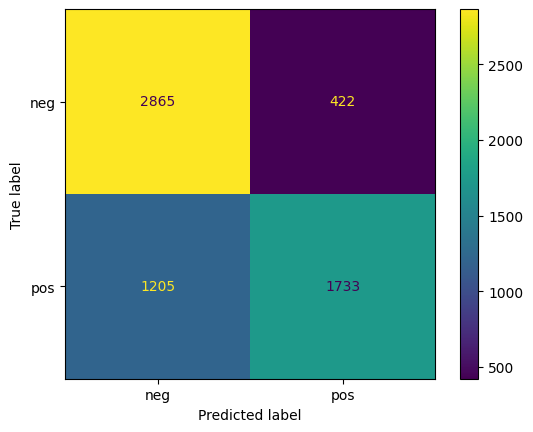

In [8]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

out = trainer.predict(dte)
pred = out.predictions.argmax(-1)
y_true = np.array(dte["label"])

print(classification_report(y_true, pred, target_names=["neg", "pos"]))
print("Macro F1:", f1_score(y_true, pred, average="macro"))
ConfusionMatrixDisplay.from_predictions(y_true, pred, display_labels=["neg", "pos"])

In [9]:
te2 = te.copy()
te2["pred"] = [id2label[i] for i in pred]
errors = te2[te2["label"] != te2["pred"]]
print(len(errors), "/", len(te2))
errors.sample(25, random_state=1)

1627 / 6225


,label,text,pred
8941,pos,صباح الخير مين نفسه في خبز جنوبي حياه الله,neg
9832,pos,ليه م نزلت اللقطة كاملة يوم طحت ومت,neg
6603,pos,. . ..كانت ك عصفور يغرد.. أحلامي كانت كلمات جم...,neg
10867,pos,اعتقد معناها ايش تقول,neg
2668,neg,سيد حسن نصرالله حتى قلبي وعيوني بعطيك وروحي بت...,pos
5255,neg,˓⸀ء كل مايرجوه المرء في نهاية المطاف، ألا يأتي...,pos
9838,pos,هه ماينفعك محزم,neg
741,neg,تحتاج خويي ؟! بفزع معك ونضبط مستقبلنا مع بعض,pos
1457,neg,فديت الروقان,pos
11142,pos,الملاكم الغاضب بسبب الخسارة دخلت عنده حبيبته ا...,neg


## 5. Save and publish the model

In [10]:
trainer.save_model("model")
tok.save_pretrained("model")

('model/tokenizer_config.json',
 'model/special_tokens_map.json',
 'model/vocab.txt',
 'model/added_tokens.json',
 'model/tokenizer.json')

In [11]:
from huggingface_hub import login
login()
model.push_to_hub("arabic-sentiment-marbert")
tok.push_to_hub("arabic-sentiment-marbert")

No files have been modified since last commit. Skipping to prevent empty commit.


CommitInfo(commit_url='https://huggingface.co/hishamx777/arabic-sentiment-marbert/commit/f130c14c56914f194db258ea7f536b367c8d612d', commit_message='Upload tokenizer', commit_description='', oid='f130c14c56914f194db258ea7f536b367c8d612d', pr_url=None, repo_url=RepoUrl('https://huggingface.co/hishamx777/arabic-sentiment-marbert', endpoint='https://huggingface.co', repo_type='model', repo_id='hishamx777/arabic-sentiment-marbert'), pr_revision=None, pr_num=None)

## 6. Demo (temporary Gradio link, runs from this notebook)

In [ ]:
import gradio as gr
from transformers import pipeline
clf_pipe = pipeline("text-classification", model="model", tokenizer=tok, device=0)
def predict(text):
    r = clf_pipe(clean(text))[0]
    return {r["label"]: float(r["score"])}

gr.Interface(predict, gr.Textbox(lines=3), gr.Label()).launch(share=True)